- <font size="3">Implementation</font>
- <font size="3">Step size</font>
- <font size="3">Convergence</font>

### Preamble

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rcdefaults()

# plt.rc('font',**{'family':'serif','serif':['Times']})
# plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

### Functions for convergence tests (see below)

In [2]:
def acc_ratio(chain):
    n = len(chain)
    
    return 1 - np.sum(chain[1:] - chain[:-1] == 0)/n  # np.diff(chain)

def chain_statistics(chain):
    
    n = int(len(chain)/4)
    
    pieces = [chain[:n],chain[n:2*n],chain[2*n:3*n],chain[3*n:]]
    
    means = [np.mean(arr) for arr in pieces]
    variances = [np.mean(arr**2) - mean**2 for arr,mean in zip(pieces,means)]
    
    return means,variances

def next_pow_two(n):
    i = 1
    while i < n:
        i = i << 1
    return i


def autocorr_func_1d(x, norm=True):
    x = np.atleast_1d(x)
    if len(x.shape) != 1:
        raise ValueError("invalid dimensions for 1D autocorrelation function")
    n = next_pow_two(len(x))

    # Compute the FFT and then (from that) the auto-correlation function
    f = np.fft.fft(x - np.mean(x), n=2 * n)
    acf = np.fft.ifft(f * np.conjugate(f))[: len(x)].real
    acf /= 4 * n

    # Optionally normalize
    if norm:
        acf /= acf[0]

    return acf

### Sampling method 3 (rejection, v2.0) a.k.a. the Metropolis--Hastings algorithm

This technique can be viewed as a random walk in the random variable $X$ whose distribution we are sampling. In the previous sampling methods, we were able to generate all individual values $x$ independently. In the MH algorithm, a new value $x'$ of the variable is sampled based on the current value $x$. In other words, the following value depends on the preceding value. Random sequences with this property are called *Markov chains*.

For this algorithm we need an auxiliary PDF, which is called *proposal PDF*. This proposal PDF will depend on both the preceding value $x$ and the following value $x'$. Hence, the notation: $q(x,x')$. A first choice for this PDF is a Gaussian in $x'$ with mean $x$ and some r.m.s. $\sigma$ (a free adjustable parameter):

$$
q(x',x) = \frac{1}{\sqrt{2\pi}\sigma}\exp{\left\{-\frac{(x-x')^2}{2\sigma^2}\right\}}\,.
$$

Note that this Gaussian proposal PDF is symmetric in $x$ and $x'$: $q(x,x')=q(x',x)$. That is, we can also say that it is a Gaussian in $x$ with mean $x'$. This symmetry property for proposal PDFs is called the detailed balance condition. In this course we will restrict ourselves to Gaussian proposal PDFs only.

Now, to sample from a given PDF $f(x)$, we do the following:

- (1) choose the first value $x=x_0$ (arbitrarily but reasonably);
- (2) generate one individual sample $x'$ from the proposal PDF $q(x',x)$;
- (3) generate a random number $r$ from the uniform distribution, $r\in[0,1]$;
- (4) compute the ratio $f(x')/f(x)$:
  - if $f(x')/f(x)>r$, accept the new value $x'$;
  - else repeat the old value $x$;
- (5) repeat steps (2)-(4) until a required number of samples is obtained. 

Caveats:

- the choice of $\sigma$. Depending on this value, it may take more or less time to generate a good array of samples. This choice can also change from one PDF $f(x)$ to another.

<u>EXAMPLE</u>

Let us use the MH algorithm to generate samples from 

$$
f(x)=\frac{1}{\pi}\frac{1}{1+x^2}\,, \qquad x\in(-\infty,+\infty)
$$

In [3]:
def f(x):
    return 1/np.pi * 1/(1+x**2)


x0 = 1
sigma = 1
sample_size = 1000000

x_old = x0
samples = [x_old]

for i in range(sample_size):
    x_new = sigma*np.random.randn() + x_old
    r = np.random.random()
    
    if f(x_new)/f(x_old) > r:
        x_old = x_new
    
    samples.append(x_old)
    
samples = np.array(samples)

Text(0, 0.5, 'PDF')

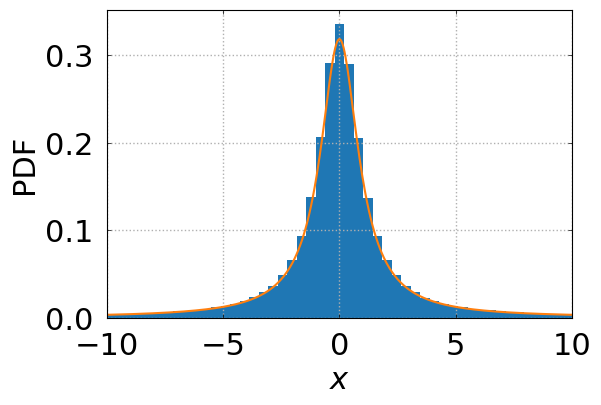

In [4]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

xmin = -10
xmax = 10
x = np.linspace(xmin,xmax,500)

ax.hist(samples, bins=np.linspace(xmin,xmax,50), density=True)
ax.plot(x, f(x))

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(xmin,xmax)

ax.set_xlabel('$x$')
ax.set_ylabel('PDF')

Text(0, 0.5, '$x$')

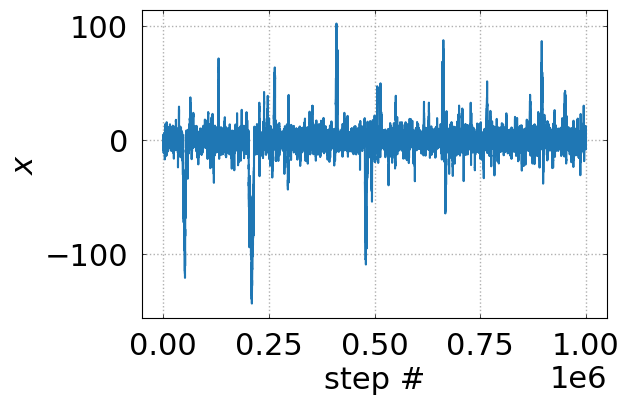

In [5]:
# Markov chain

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(samples)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('step #')
ax.set_ylabel('$x$')

<u>EXERCISE</u>

1. Experiment with different values of $\sigma$. What happens if you go to $\sigma>>1$ or $\sigma<<1$ (keeping the number of steps fixed)?
2. Experiment with the number of steps. Set $\sigma$ to a reasonable value that seem to sample the PDF well with the current number of steps. What happens if you decrease the number of steps?
3. Experiment sampling from a Gaussian $f(x)$ with a mean of $2$ and $\sigma_f=\sqrt{2}$ (note that this Gaussian is the $f(x)$ we are sampling from, not the proposal PDF $q(x',x)$; the proposal PDF is the same). Can we adjust the parameters (the proposal's $\sigma$ and $\#$ of steps to sample faster than from the PDF in the example?)

<u>EXAMPLE</u>

Let us use the MH algorithm to sample from a uniform distribution on $[3,7]$.

In [6]:
def f(x):
    if 3<x<7:
        return 1.
    else:
        return 0.


x0 = 0.
sigma = 1
sample_size = 1000000

x_old = x0
samples = [x_old]

for i in range(sample_size):
    x_new = sigma*np.random.randn() + x_old
    r = np.random.random()
    
    try:
        if f(x_new)/f(x_old) > r:
            x_old = x_new
    except ZeroDivisionError:
        print("CAN'T DIVIDE BY ZERO!")
        break
    
    samples.append(x_old)
    
samples = np.array(samples)

CAN'T DIVIDE BY ZERO!


Let's modify step (4) of the algorithm as follows:

- (4) compute the difference $\log{f(x')}-\log{f(x)}$:
  - if $\log{f(x')}-\log{f(x)}>\log{r}$, accept the new value $x'$;
  - else repeat the old value $x$;

In [7]:
def log_f(x):
    if 3<x<7:
        return 0.
    else:
        return -np.inf

x0 = 0.
sigma = 1.5
sample_size = 10000

x_old = x0
samples = [x_old]

for i in range(sample_size):
    x_new = sigma*np.random.randn() + x_old
    r = np.random.random()
    
    try:
        if log_f(x_new)-log_f(x_old) > np.log(r):
            x_old = x_new
    except ZeroDivisionError:
        print("CAN'T DIVIDE BY ZERO!")
        break
    
    samples.append(x_old)
    
samples = np.array(samples)

Text(0, 0.5, 'PDF')

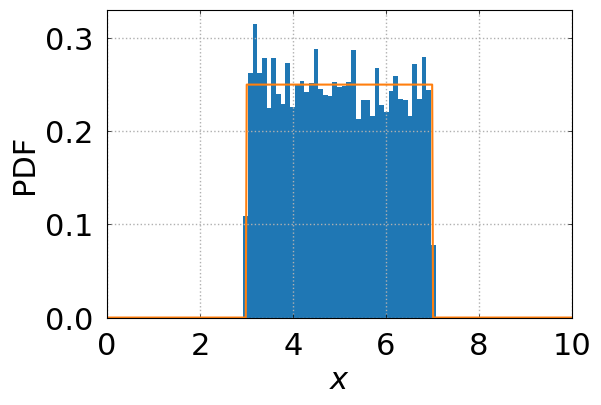

In [8]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

xmin = 0
xmax = 10
x = np.linspace(xmin,xmax,500)
f_values = [10**log_f(xx)/4 for xx in x]

ax.hist(samples, bins=np.linspace(xmin,xmax,100), density=True)
ax.plot(x, f_values)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(xmin,xmax)

ax.set_xlabel('$x$')
ax.set_ylabel('PDF')

Text(0, 0.5, '$x$')

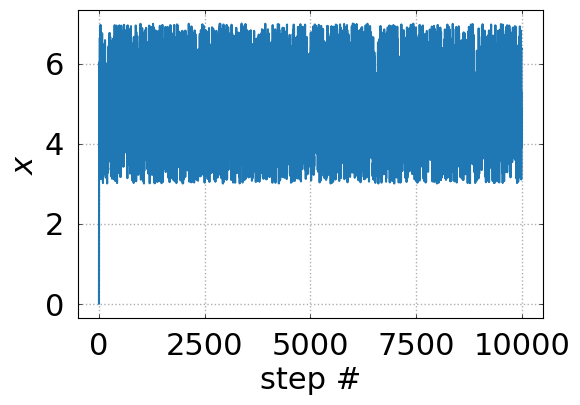

In [9]:
# Markov chain

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(samples)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('step #')
ax.set_ylabel('$x$')

<u>EXERCISE</u>

Try to sample for a PDF that is $1$ everywhere. Plot the Markov chain as a function of the step. What is happening?

### Convergence

#### Acceptance ratio

- if it's around 1, we accept steps too often, i.e. not getting enough samples around each value of $x$;
- if it's around 0, we almost always reject, i.e. spending too much time around one value of $x$;

The Goldilocks value: $\approx 0.25$

In [10]:
acc_ratio(samples)

0.7007299270072993

#### Comparing the mean and variance for different parts of a chain

If we sampled enough, different chunks of a chain should have similar values of the mean and the r.m.s. deviation from it.

In [11]:
chain_statistics(samples)

([4.916935351449965, 4.941538898932658, 5.023015207011116, 4.971392799682222],
 [1.427352409865342,
  1.3236487983691203,
  1.4148706975568393,
  1.3161948716911376])

#### Autocorrelation time

Two consecutive samples obviously related (the next one is sampled from a proposal distribution centered on the previous one). The autocorrelation time $\tau_c$ is the number of steps required to produce $\approx$ an independent sample.

The estimate of $\tau_c$ becomes more or less adequate when the chain is at least $50\tau_c$.

We want:

- to adjust the proposal PDF to get a shorter $\tau_c$ (the shorter the better);
- run the sampler for at least $50\tau_c$ (the longer the better);

Text(0, 0.5, 'ACF')

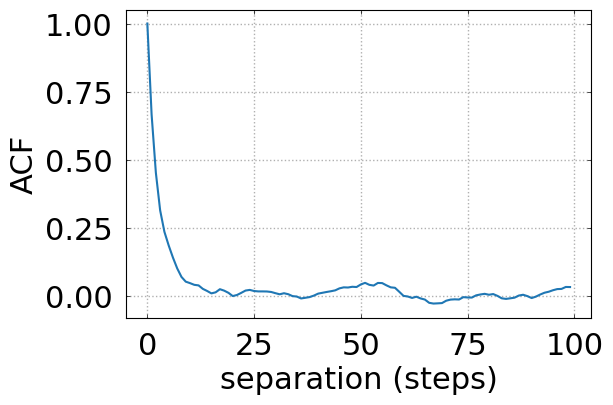

In [13]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(autocorr_func_1d(samples)[:100])

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('separation (steps)')
ax.set_ylabel('ACF')

In [15]:
1 + 2*np.sum(autocorr_func_1d(samples)[:20])

7.9105845276564075

<u>EXERCISE</u>

Using the convergence criteria, assess convergence for one or more chains obtained above.

<u>*EXERCISE</u>



### Home exercises

One of the exercices above.